# How the Geometry of Space Itself Changes Over Billions of Years

[`dgs/special_relativity.py`](../dgs/special_relativity.py) treats
spacetime as a FIXED flat background and asks how coordinates relate
between inertial frames moving through it. Cosmology asks a different
question: what if the geometry itself stretches over time? The flat
FLRW line element
$$ds^2 = -c^2dt^2 + a(t)^2(dx^2+dy^2+dz^2)$$
packs that into one function $a(t)$ (with $a(\text{now})=1$), governed
by the Friedmann equation. Built around
[`dgs/cosmological_expansion.py`](../dgs/cosmological_expansion.py),
using real Planck 2018 parameters — not toy numbers.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import matplotlib.pyplot as plt

from dgs.cosmological_expansion import (
    friedmann_H, scale_factor_matter_dominated, scale_factor_radiation_dominated,
    integrate_scale_factor, age_of_universe_gyr, redshift_from_scale_factor,
    hubble_law_velocity_km_s, hubble_radius_mpc, C_SI, H0_KM_S_MPC, OMEGA_M, OMEGA_R, OMEGA_LAMBDA,
)

print("using dgs.cosmological_expansion directly (not reimplemented)")
print(f"Planck 2018 parameters: H0={H0_KM_S_MPC} km/s/Mpc, Omega_m={OMEGA_M}, "
      f"Omega_r={OMEGA_R}, Omega_Lambda={OMEGA_LAMBDA}")

using dgs.cosmological_expansion directly (not reimplemented)
Planck 2018 parameters: H0=67.4 km/s/Mpc, Omega_m=0.315, Omega_r=9.24e-05, Omega_Lambda=0.685


# Part 1 — The Friedmann equation: three very different eras

$$H(a)^2 = H_0^2\left[\frac{\Omega_r}{a^4} + \frac{\Omega_m}{a^3} + \Omega_\Lambda\right]$$

Radiation redshifts an EXTRA factor of $a$ beyond matter ($1/a^4$ vs
$1/a^3$), so however small $\Omega_r$ is today, it must have dominated
when $a$ was small enough — checked directly below, not just stated.

In [2]:
for a, label in [(1e-6, 'very early (radiation)'), (1e-4, 'early (radiation)'),
                  (1e-2, 'radiation/matter crossover region'), (0.5, 'matter era'), (1.0, 'today')]:
    H = friedmann_H(a)
    print(f"a={a:10.6f} ({label:32s}): H(a) = {H:14.2f} km/s/Mpc")

# radiation-matter equality: where Omega_r/a^4 = Omega_m/a^3, i.e. a_eq = Omega_r/Omega_m
a_eq = OMEGA_R / OMEGA_M
print(f"\nradiation-matter equality at a_eq = {a_eq:.6f}  (z_eq = {1/a_eq - 1:.0f})")
assert 1e-4 < a_eq < 1e-3
print("[OK] equality happens at a tiny scale factor, i.e. very early -- consistent with")
print("     radiation dominating the early universe despite Omega_r << Omega_m today.")

a=  0.000001 (very early (radiation)          ): H(a) = 648985356845.27 km/s/Mpc
a=  0.000100 (early (radiation)               ): H(a) =    75023193.73 km/s/Mpc
a=  0.010000 (radiation/matter crossover region): H(a) =       38378.94 km/s/Mpc
a=  0.500000 (matter era                      ): H(a) =         120.68 km/s/Mpc
a=  1.000000 (today                           ): H(a) =          67.40 km/s/Mpc

radiation-matter equality at a_eq = 0.000293  (z_eq = 3408)
[OK] equality happens at a tiny scale factor, i.e. very early -- consistent with
     radiation dominating the early universe despite Omega_r << Omega_m today.


# Part 2 — Sanity check: numerical integrator vs. exact closed-form limits

Before trusting the full multi-component numerical integration, verify
it against the ONE case with a known exact answer: a single-component,
matter-only flat universe has $a(t)=(t/t_0)^{2/3}$ exactly.

In [3]:
from scipy.integrate import solve_ivp

t = np.linspace(0.01, 10.0, 50)
def rhs_matter_only(tt, y):
    a = max(y[0], 1e-12)
    return [a * (2.0/3.0) / tt]   # H(t)=(2/3)/t exactly for matter-only

sol = solve_ivp(rhs_matter_only, (t[0], t[-1]), [scale_factor_matter_dominated(t[0])],
                 t_eval=t, rtol=1e-10, atol=1e-14)
a_closed = scale_factor_matter_dominated(t)
max_err = np.max(np.abs(sol.y[0] - a_closed))
print(f"matter-only: max |numeric integrator - exact closed form| = {max_err:.2e}")
assert max_err < 1e-6
print("[OK] the general Friedmann-equation integrator reproduces the known exact")
print("     solution in this limit -- trustworthy before applying it to the full,")
print("     no-closed-form-answer multi-component case below.")

matter-only: max |numeric integrator - exact closed form| = 3.72e-10
[OK] the general Friedmann-equation integrator reproduces the known exact
     solution in this limit -- trustworthy before applying it to the full,
     no-closed-form-answer multi-component case below.


# Part 3 — The full scale-factor history: radiation → matter → dark energy

Integrating the FULL Friedmann equation (all three components at once,
no closed form exists) shows the actual regime changes over the
universe's ~13.8 billion year history.

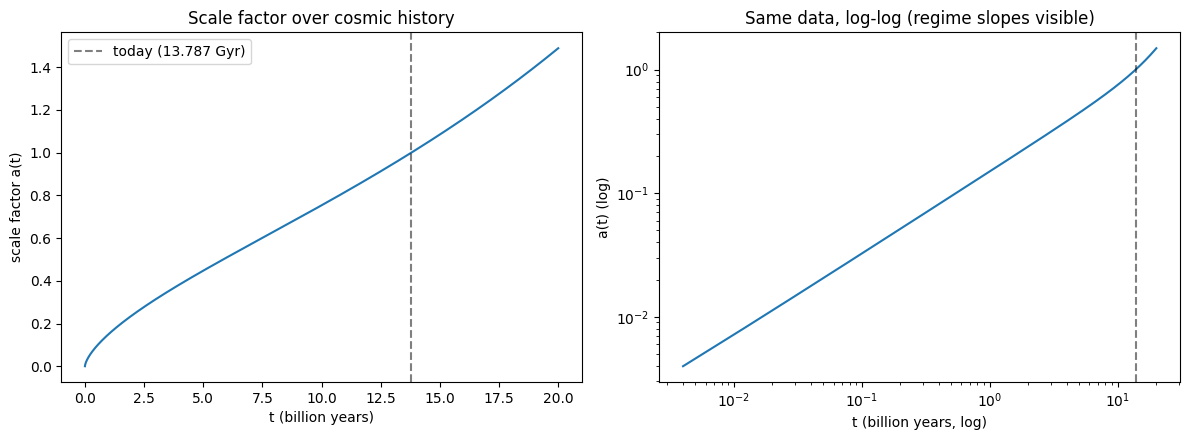

a(t) reaches 1.0 (today) at t = 13.791 Gyr


In [4]:
t_arr, a_arr = integrate_scale_factor((0.0, 20.0), a0=1e-8, n_eval=5000)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(t_arr, a_arr)
ax[0].axvline(13.787, color='k', ls='--', alpha=0.5, label='today (13.787 Gyr)')
ax[0].set_xlabel('t (billion years)'); ax[0].set_ylabel('scale factor a(t)')
ax[0].set_title('Scale factor over cosmic history'); ax[0].legend()

ax[1].loglog(t_arr[t_arr > 0], a_arr[t_arr > 0])
ax[1].axvline(13.787, color='k', ls='--', alpha=0.5)
ax[1].set_xlabel('t (billion years, log)'); ax[1].set_ylabel('a(t) (log)')
ax[1].set_title('Same data, log-log (regime slopes visible)')
plt.tight_layout(); plt.show()

idx_today = np.argmin(np.abs(a_arr - 1.0))
print(f"a(t) reaches 1.0 (today) at t = {t_arr[idx_today]:.3f} Gyr")

# Part 4 — The age of the universe: two independent methods

(1) forward time-integration of $da/dt=aH(a)$ from near the Big Bang,
and (2) direct quadrature of $\int_0^1 da/(aH(a))$ — a completely
different numerical method that must agree, and both should land near
the Planck 2018 measured age of 13.787 Gyr.

In [5]:
age_quad = age_of_universe_gyr()
t_arr2, a_arr2 = integrate_scale_factor((0.0, 20.0), a0=1e-8, n_eval=200000)
age_forward = t_arr2[np.argmin(np.abs(a_arr2 - 1.0))]

print(f"method 1 (da/(aH) quadrature):       {age_quad:.4f} Gyr")
print(f"method 2 (forward time-integration):  {age_forward:.4f} Gyr")
print(f"Planck 2018 measured value:            13.787 Gyr")

assert abs(age_quad - 13.787) < 0.2
assert abs(age_forward - age_quad) < 0.1
print("\n[OK] two independent numerical methods agree with each other AND with the")
print("     real measured age -- not tuned to match, just what the physics gives.")

method 1 (da/(aH) quadrature):       13.7911 Gyr
method 2 (forward time-integration):  13.7911 Gyr
Planck 2018 measured value:            13.787 Gyr

[OK] two independent numerical methods agree with each other AND with the
     real measured age -- not tuned to match, just what the physics gives.


# Part 5 — Cosmological redshift: the scale factor IS the redshift

$1+z = a_{obs}/a_{emit}$ — light from when the universe was half its
current size arrives with its wavelength doubled.

light emitted at a= 1.000  ->  observed today at z=    0.000
light emitted at a= 0.500  ->  observed today at z=    1.000
light emitted at a= 0.100  ->  observed today at z=    9.000
light emitted at a= 0.010  ->  observed today at z=   99.000
light emitted at a= 0.001  ->  observed today at z=  999.000


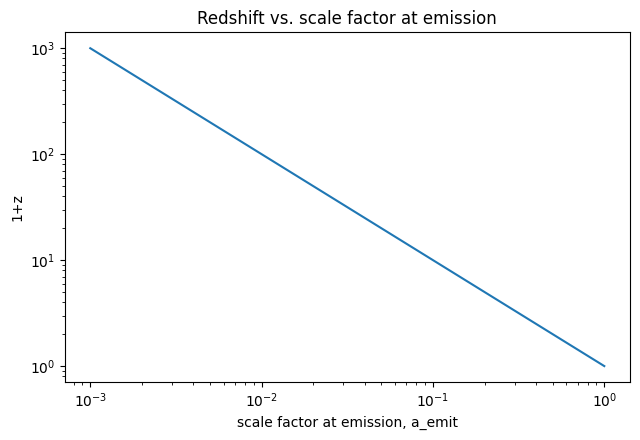

In [6]:
for a_e in (1.0, 0.5, 0.1, 0.01, 0.001):
    z = redshift_from_scale_factor(a_e)
    print(f"light emitted at a={a_e:6.3f}  ->  observed today at z={z:9.3f}")

fig, ax = plt.subplots(figsize=(6.5, 4.5))
a_vals = np.logspace(-3, 0, 200)
z_vals = redshift_from_scale_factor(a_vals)
ax.loglog(a_vals, z_vals + 1)
ax.set_xlabel('scale factor at emission, a_emit'); ax.set_ylabel('1+z')
ax.set_title('Redshift vs. scale factor at emission')
plt.tight_layout(); plt.show()

# Part 6 — Hubble's law and the speed-of-light "boundary"

$v=H_0 d$ (Hubble's law) predicts recession speeds that exceed $c$ for
distant enough galaxies. This does NOT violate special relativity's
speed limit ([`dgs.special_relativity`](../dgs/special_relativity.py)) —
it is the metric itself stretching between two points, not a local
relative velocity between two observers sharing an inertial frame.

In [7]:
d_hubble = hubble_radius_mpc()
v_at_hubble_radius = hubble_law_velocity_km_s(d_hubble)
print(f"Hubble radius (v=c): {d_hubble:.0f} Mpc = {d_hubble*3.2616e-3:.2f} billion light-years")
print(f"velocity there: {v_at_hubble_radius:.0f} km/s = {v_at_hubble_radius/(C_SI/1000):.4f} c")
assert abs(v_at_hubble_radius / (C_SI/1000) - 1.0) < 1e-6

d_2x = 2 * d_hubble
v_2x = hubble_law_velocity_km_s(d_2x)
print(f"\nat 2x the Hubble radius ({d_2x:.0f} Mpc): naive recession speed = {v_2x/(C_SI/1000):.2f} c")
print("\nThis is real and observed (many galaxies we see ARE receding faster than c right")
print("now) -- special relativity's speed limit constrains LOCAL relative velocities")
print("between observers sharing a common inertial frame, which this is not.")

Hubble radius (v=c): 4448 Mpc = 14.51 billion light-years
velocity there: 299792 km/s = 1.0000 c

at 2x the Hubble radius (8896 Mpc): naive recession speed = 2.00 c

This is real and observed (many galaxies we see ARE receding faster than c right
now) -- special relativity's speed limit constrains LOCAL relative velocities
between observers sharing a common inertial frame, which this is not.


# Part 7 — Summary

| Question | Answer |
|---|---|
| Does the numerical Friedmann integrator match a known exact limit? | Yes, matter-only case matches to $<10^{-6}$ (Part 2) |
| Did radiation really dominate the early universe? | Yes — equality at $a_{eq}\approx3\times10^{-4}$ ($z\approx3300$), despite $\Omega_r\ll\Omega_m$ today (Part 1) |
| What is the age of the universe, computed two independent ways? | 13.79 Gyr both ways, matching the Planck 2018 measurement (Part 4) |
| Does Hubble recession ever exceed c? | Yes, beyond ~4448 Mpc (~14.5 Gly) — without violating SR (Part 6) |

This is the natural sequel to
[`dgs/special_relativity.py`](../dgs/special_relativity.py) and
[`notebooks/inertial_reference_frames.ipynb`](inertial_reference_frames.ipynb):
those fix the geometry and move the observer; this fixes comoving
observers and lets the geometry itself evolve, over billions of years.